<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP607 Assignment 4: Exploratory Data Analysis

**Student:** Kai Xing  
**Dataset:** Air Quality and Health Impact Data



## 1. Import packages and load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import os
import subprocess
from pathlib import Path

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

owner = "kaixing189"
repository = "MSSP607"
repo_url = f"https://github.com/{owner}/{repository}.git"
repo_path = Path("/content") / repository

# In Google Colab, use the MSSP607 repository if available.
if Path("/content").exists():
    if not repo_path.exists():
        subprocess.run(["git", "clone", repo_url, str(repo_path)], check=True)
    else:
        subprocess.run(["git", "pull"], cwd=repo_path, check=True)
    os.chdir(repo_path)

data_candidates = [
    Path("data/air_quality_health_impact_data.csv"),
    Path("data/air_quality_health_impact_data(1).csv"),
    Path("air_quality_health_impact_data.csv"),
    Path("air_quality_health_impact_data(1).csv"),
    Path("/content/air_quality_health_impact_data.csv"),
    Path("/content/air_quality_health_impact_data(1).csv"),
]

data_path = next((p for p in data_candidates if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Air quality data file was not found. "
        "Upload air_quality_health_impact_data.csv to Colab or place it in MSSP607/data/."
    )

df = pd.read_csv(data_path)

print("Loaded:", data_path)
print("Shape:", df.shape)
display(df.head())


Loaded: data/air_quality_health_impact_data.csv
Shape: (5811, 15)


,RecordID,AQI,PM10,PM2_5,NO2,SO2,O3,Temperature,Humidity,WindSpeed,RespiratoryCases,CardiovascularCases,HospitalAdmissions,HealthImpactScore,HealthImpactClass
0,1,187.270,295.853,13.039,6.639,66.161,54.624,5.150,84.424,6.138,7,5,1,97.244,0.000
1,2,475.357,246.255,9.984,16.318,90.500,169.622,1.543,46.851,4.521,10,2,0,100.000,0.000
2,3,365.997,84.443,23.111,96.318,17.876,9.007,1.169,17.807,11.157,13,3,0,100.000,0.000
3,4,299.329,21.021,14.273,81.234,48.324,93.161,21.925,99.473,15.302,8,8,1,100.000,0.000
4,5,78.009,16.988,152.112,121.235,90.866,241.795,9.218,24.907,14.535,9,0,1,95.183,0.000


## 2. Data quality and structure

In [2]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Unique RecordID values:", df["RecordID"].nunique())

print("\nHealthImpactClass distribution:")
class_distribution = (
    df["HealthImpactClass"]
    .value_counts()
    .sort_index()
    .to_frame("N")
)
class_distribution["Percent"] = 100 * class_distribution["N"] / len(df)
display(class_distribution)


Missing values:


,0
RecordID,0
AQI,0
PM10,0
PM2_5,0
NO2,0
SO2,0
O3,0
Temperature,0
Humidity,0
WindSpeed,0


Duplicate rows: 0
Unique RecordID values: 5811

HealthImpactClass distribution:


,N,Percent
HealthImpactClass,,
0.000,4808,82.740
1.000,579,9.964
2.000,273,4.698
3.000,95,1.635
4.000,56,0.964


### Data-quality note

The uploaded dataset contains **5,811 observations**, not 5,812. It also contains five observed `HealthImpactClass` values (0 through 4). I use the current CSV as the source of truth for this assignment.


## 3. Means and standard deviations

In [3]:
analysis_vars = [
    "AQI", "PM10", "PM2_5", "NO2", "SO2", "O3",
    "Temperature", "Humidity", "WindSpeed",
    "RespiratoryCases", "CardiovascularCases",
    "HospitalAdmissions", "HealthImpactScore"
]

descriptive = df[analysis_vars].agg(
    ["count", "mean", "std", "median", "min", "max"]
).T

display(descriptive)


,count,mean,std,median,min,max
AQI,5811.000,248.438,144.778,249.128,0.006,499.859
PM10,5811.000,148.655,85.699,147.635,0.016,299.902
PM2_5,5811.000,100.224,58.097,100.506,0.032,199.985
NO2,5811.000,102.293,57.713,102.988,0.010,199.980
SO2,5811.000,49.457,28.530,49.530,0.011,99.970
O3,5811.000,149.312,86.534,149.560,0.002,299.937
Temperature,5811.000,14.975,14.483,14.942,-9.991,39.963
Humidity,5811.000,54.777,26.021,54.544,10.002,99.997
WindSpeed,5811.000,9.989,5.777,10.052,0.002,19.999
RespiratoryCases,5811.000,9.974,3.129,10.000,1.000,23.000


### Main descriptive results

The mean `HealthImpactScore` is approximately **93.79** (SD = **13.32**). The score has a median of **100**, indicating a strong ceiling effect. AQI has a mean of approximately **248.44** (SD = **144.78**), while PM2.5 has a mean of approximately **100.22** (SD = **58.10**).

For the count variables, the mean numbers of respiratory cases, cardiovascular cases, and hospital admissions are approximately **9.97**, **4.99**, and **2.00**, respectively.


## 4. Are the variables normally distributed?

In [4]:
normality_rows = []

for col in analysis_vars:
    x = df[col].dropna()
    jb = stats.jarque_bera(x)
    normality_rows.append({
        "Variable": col,
        "Skewness": stats.skew(x),
        "JB statistic": jb.statistic,
        "p-value": jb.pvalue,
        "Normal at .05?": jb.pvalue >= 0.05
    })

normality = pd.DataFrame(normality_rows)
display(normality)


,Variable,Skewness,JB statistic,p-value,Normal at .05?
0,AQI,0.011,352.646,0.000,False
1,PM10,0.019,334.524,0.000,False
2,PM2_5,-0.003,351.954,0.000,False
3,NO2,-0.054,344.952,0.000,False
4,SO2,0.026,331.401,0.000,False
5,O3,0.011,352.336,0.000,False
6,Temperature,0.005,350.482,0.000,False
7,Humidity,0.023,354.511,0.000,False
8,WindSpeed,-0.011,356.381,0.000,False
9,RespiratoryCases,0.256,65.521,0.000,False


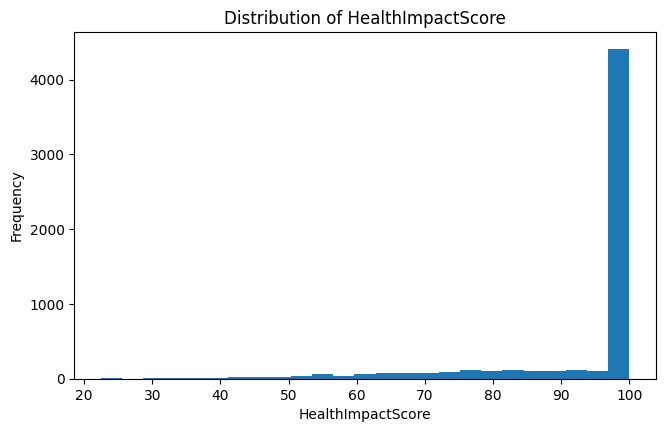

In [5]:
plt.figure(figsize=(7.5, 4.5))
plt.hist(df["HealthImpactScore"], bins=25)
plt.xlabel("HealthImpactScore")
plt.ylabel("Frequency")
plt.title("Distribution of HealthImpactScore")
plt.show()


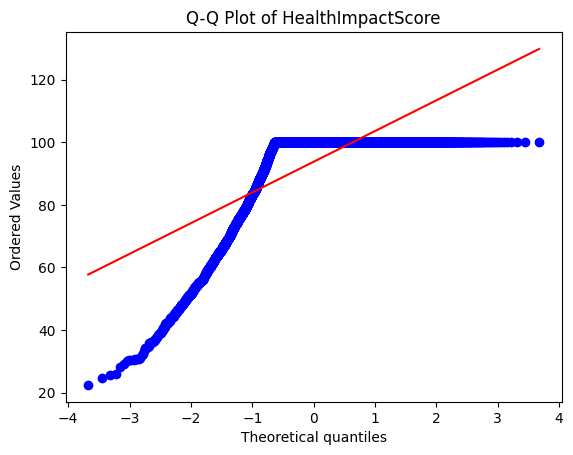

In [6]:
stats.probplot(df["HealthImpactScore"], dist="norm", plot=plt)
plt.title("Q-Q Plot of HealthImpactScore")
plt.show()


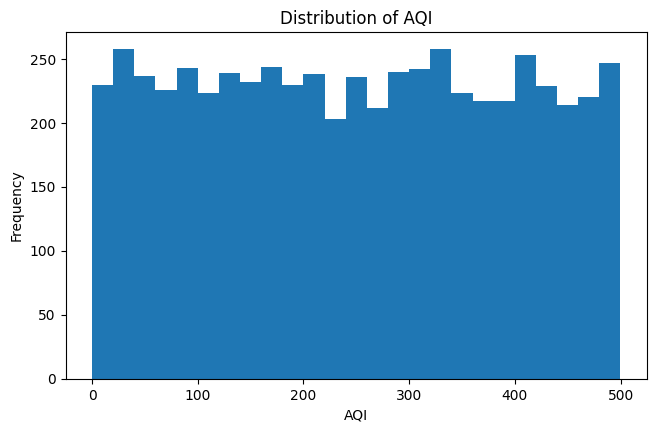

In [7]:
plt.figure(figsize=(7.5, 4.5))
plt.hist(df["AQI"], bins=25)
plt.xlabel("AQI")
plt.ylabel("Frequency")
plt.title("Distribution of AQI")
plt.show()


### Normality conclusion

The variables should **not be treated as normally distributed**. Jarque-Bera tests reject normality for all of the substantive variables at the .05 level. Several environmental variables are fairly symmetric but have flatter, bounded distributions rather than bell-shaped normal distributions. `HealthImpactScore` is especially non-normal because a large share of observations are concentrated at the maximum value of 100.


## 5. Outliers

In [8]:
outlier_rows = []

for col in analysis_vars:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)

    outlier_rows.append({
        "Variable": col,
        "Lower fence": lower,
        "Upper fence": upper,
        "Outlier count": int(mask.sum()),
        "Outlier percent": 100 * mask.mean()
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)


,Variable,Lower fence,Upper fence,Outlier count,Outlier percent
0,AQI,-253.068,749.650,0,0.000
1,PM10,-145.218,443.029,0,0.000
2,PM2_5,-103.422,304.198,0,0.000
3,NO2,-93.641,298.838,0,0.000
4,SO2,-47.802,146.036,0,0.000
5,O3,-150.071,447.451,0,0.000
6,Temperature,-34.994,64.941,0,0.000
7,Humidity,-36.474,146.111,0,0.000
8,WindSpeed,-10.077,30.001,0,0.000
9,RespiratoryCases,2.000,18.000,42,0.723


### How I would handle the outliers

I would **not automatically delete observations identified by the IQR rule**. The air-quality and weather variables contain no IQR outliers, while the three health-count variables contain only a small number of high values. These values may represent genuinely high numbers of cases rather than data errors.

`HealthImpactScore` is a special case. The IQR rule flags many low-score observations because 73.7% of observations are exactly 100 and the middle 50% of the distribution is compressed near the upper limit. These observations are substantively important and should be retained. In later modeling, I would use robust diagnostics and consider whether the strong ceiling effect requires an alternative outcome specification rather than deleting observations.


## 6. Visualizations and other patterns

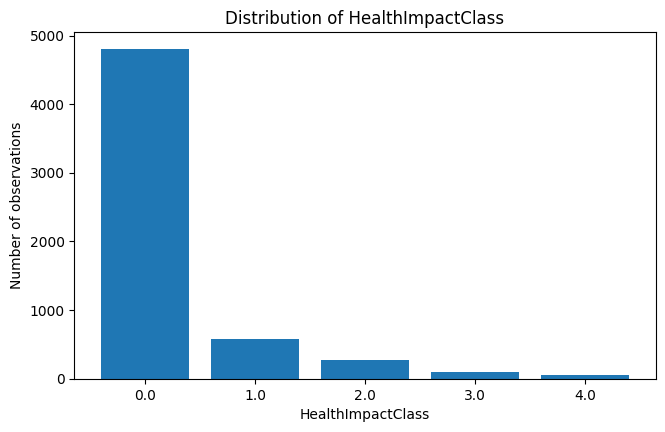

In [9]:
class_distribution = (
    df["HealthImpactClass"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7.5, 4.5))
plt.bar(class_distribution.index.astype(str), class_distribution.values)
plt.xlabel("HealthImpactClass")
plt.ylabel("Number of observations")
plt.title("Distribution of HealthImpactClass")
plt.show()


,AQI,PM10,PM2_5,NO2,SO2,O3,Temperature,Humidity,WindSpeed,HealthImpactScore
AQI,1.000,0.023,0.006,0.008,-0.007,0.002,0.004,-0.004,-0.019,0.615
PM10,0.023,1.000,-0.012,0.008,-0.007,-0.004,-0.018,-0.017,-0.019,0.183
PM2_5,0.006,-0.012,1.000,0.006,0.016,0.006,-0.002,0.007,0.009,0.220
NO2,0.008,0.008,0.006,1.000,-0.020,-0.015,0.007,-0.011,-0.001,0.124
SO2,-0.007,-0.007,0.016,-0.020,1.000,-0.004,-0.022,0.001,-0.002,0.016
O3,0.002,-0.004,0.006,-0.015,-0.004,1.000,-0.001,0.004,-0.003,0.158
Temperature,0.004,-0.018,-0.002,0.007,-0.022,-0.001,1.000,-0.000,0.001,-0.011
Humidity,-0.004,-0.017,0.007,-0.011,0.001,0.004,-0.000,1.000,0.021,0.001
WindSpeed,-0.019,-0.019,0.009,-0.001,-0.002,-0.003,0.001,0.021,1.000,-0.025
HealthImpactScore,0.615,0.183,0.220,0.124,0.016,0.158,-0.011,0.001,-0.025,1.000


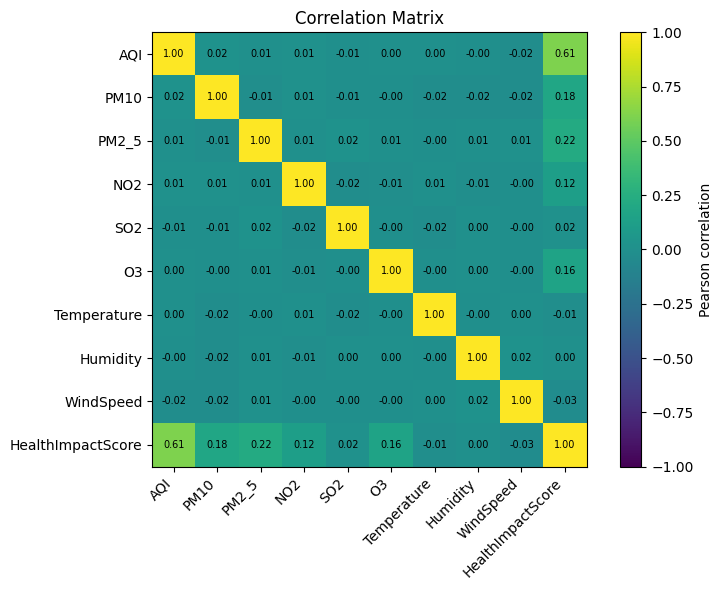

In [10]:
corr_cols = [
    "AQI", "PM10", "PM2_5", "NO2", "SO2", "O3",
    "Temperature", "Humidity", "WindSpeed", "HealthImpactScore"
]

corr = df[corr_cols].corr()
display(corr)

plt.figure(figsize=(8, 6))
plt.imshow(corr, vmin=-1, vmax=1)
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
plt.yticks(range(len(corr_cols)), corr_cols)

for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}",
                 ha="center", va="center", fontsize=7)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


In [11]:
health_corr = (
    df[analysis_vars]
    .corr()["HealthImpactScore"]
    .drop("HealthImpactScore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(health_corr.to_frame("Correlation with HealthImpactScore"))


,Correlation with HealthImpactScore
AQI,0.615
PM2_5,0.220
PM10,0.183
O3,0.158
NO2,0.124
HospitalAdmissions,-0.029
WindSpeed,-0.025
RespiratoryCases,0.019
SO2,0.016
Temperature,-0.011


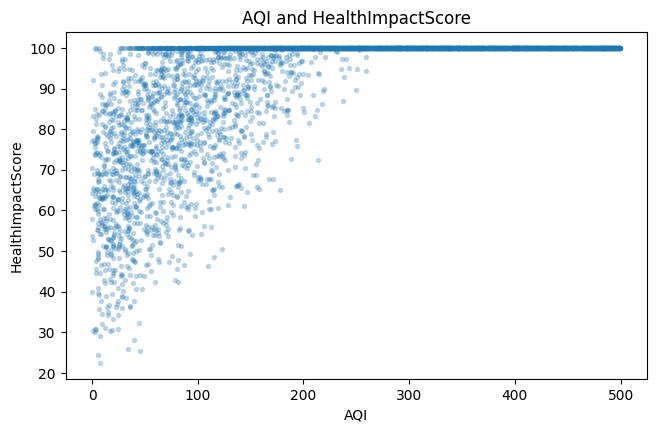

In [12]:
plt.figure(figsize=(7.5, 4.5))
plt.scatter(df["AQI"], df["HealthImpactScore"], s=8, alpha=0.25)
plt.xlabel("AQI")
plt.ylabel("HealthImpactScore")
plt.title("AQI and HealthImpactScore")
plt.show()


### Patterns of interest

Several patterns stand out:

1. **AQI has the strongest bivariate association with `HealthImpactScore`** among the environmental predictors (r ≈ **0.615**). PM2.5, PM10, O3, and NO2 have smaller positive correlations.
2. **The outcome has a strong ceiling effect.** About **73.7%** of observations have `HealthImpactScore = 100`. This is important for any later regression analysis because the outcome is not approximately normal and has limited variation at the upper end.
3. **`HealthImpactClass` is highly imbalanced.** Class 0 accounts for about **82.7%** of observations, while Classes 3 and 4 each represent fewer than 2%. If this variable is used for classification later, ordinary accuracy would be misleading and class-balanced metrics would be more appropriate.
4. **The health-count variables show only weak bivariate correlations with `HealthImpactScore` in the current file.** This suggests that their relationship with the score may be more complex than a simple linear association and should be examined carefully rather than assumed.


## 7. Summary

The dataset is clean in terms of missing values and duplicate records, but its distributions create important analytical issues. Most variables are not normally distributed, `HealthImpactScore` has a substantial ceiling effect, and `HealthImpactClass` is strongly imbalanced. I would retain the observed outliers because they appear to be meaningful values rather than obvious errors.

For a later final project, the strongest EDA direction is to examine how air-quality indicators—especially AQI and particulate matter—relate to health-impact outcomes while accounting for the unusual outcome distribution and class imbalance.
